# 06: Preprocess modalities

In [1]:
import spatialdata as sd
import spatialdata_plot
from pathlib import Path
import scanpy as sc
import scanpy.external as sce
import anndata as ad
import pandas as pd
from spatialdata.models import TableModel

import pycytominer
from pycytominer.operations import RobustMAD

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/importlib/__init__.py:126: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  return _bootstrap._gcd_import(name[level:], package, level)


## 06A: Get data

In [7]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

In [8]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1_subset_baked_cropped.zarr")
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2_subset_baked_cropped.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


In [73]:
sample1_gexp = sdata_sample1.tables["table_subset"]
sample1_gexp

AnnData object with n_obs × n_vars = 60997 × 380
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden', 'Adipocytes_score', 'B_cells_score', 'Breast_cancer_score', 'Breast_glandular_cells_score', 'Breast_myoepithelial_cells_score', 'Dendritic_cells_score', 'Endothelial_cells_score', 'Epithelial_cells_score', 'Fibroblasts_score', 'Immune_cells_score', 'Macrophages_score', 'Mast_cells_score', 'Monocytes_score', 'NK_cells_score', 'Smooth_muscle_cells_score', 'T_cells_score', 'predicted_celltype'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log

In [74]:
sample1_morphology = ad.read_h5ad(data_dir / "xenium_sample1_subset_morphology.h5ad") 
sample1_morphology

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 60997 × 957
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden', 'Adipocytes_score', 'B_cells_score', 'Breast_cancer_score', 'Breast_glandular_cells_score', 'Breast_myoepithelial_cells_score', 'Dendritic_cells_score', 'Endothelial_cells_score', 'Epithelial_cells_score', 'Fibroblasts_score', 'Immune_cells_score', 'Macrophages_score', 'Mast_cells_score', 'Monocytes_score', 'NK_cells_score', 'Smooth_muscle_cells_score', 'T_cells_score', 'predicted_celltype'

In [56]:
sample2_gexp = sdata_sample2.tables["table_subset"]
sample2_gexp

AnnData object with n_obs × n_vars = 52206 × 380
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden', 'Adipocytes_score', 'B_cells_score', 'Breast_cancer_score', 'Breast_glandular_cells_score', 'Breast_myoepithelial_cells_score', 'Dendritic_cells_score', 'Endothelial_cells_score', 'Epithelial_cells_score', 'Fibroblasts_score', 'Immune_cells_score', 'Macrophages_score', 'Mast_cells_score', 'Monocytes_score', 'NK_cells_score', 'Smooth_muscle_cells_score', 'T_cells_score', 'predicted_celltype'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log

In [75]:
sample2_morphology = ad.read_h5ad(data_dir / "xenium_sample2_subset_morphology.h5ad") 
sample2_morphology

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 52206 × 957
    obs: 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden', 'Adipocytes_score', 'B_cells_score', 'Breast_cancer_score', 'Breast_glandular_cells_score', 'Breast_myoepithelial_cells_score', 'Dendritic_cells_score', 'Endothelial_cells_score', 'Epithelial_cells_score', 'Fibroblasts_score', 'Immune_cells_score', 'Macrophages_score', 'Mast_cells_score', 'Monocytes_score', 'NK_cells_score', 'Smooth_muscle_cells_score', 'T_cells_score', 'predicted_celltype', 'cell_id'

### Load and merge gexp

In [14]:
adata_gexp_raw = ad.concat([sample1_gexp, sample2_gexp])

adata_gexp_raw.write(data_dir / "10x_adata_gexp_raw.h5ad")
adata_gexp_raw

AnnData object with n_obs × n_vars = 113203 × 380
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden', 'Adipocytes_score', 'B_cells_score', 'Breast_cancer_score', 'Breast_glandular_cells_score', 'Breast_myoepithelial_cells_score', 'Dendritic_cells_score', 'Endothelial_cells_score', 'Epithelial_cells_score', 'Fibroblasts_score', 'Immune_cells_score', 'Macrophages_score', 'Mast_cells_score', 'Monocytes_score', 'NK_cells_score', 'Smooth_muscle_cells_score', 'T_cells_score', 'predicted_celltype'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    layers: 'counts'

## Preprocessing

### Gene expression: Run Scanpy workflow
following https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering.html

In [16]:
adata_gexp_raw.var["mt"] = adata_gexp_raw.var_names.str.startswith("MT-")
adata_gexp_raw.var["ribo"] = adata_gexp_raw.var_names.str.startswith(("RPS", "RPL"))
adata_gexp_raw.var["hb"] = adata_gexp_raw.var_names.str.contains("^HB[^(P)]")

In [18]:
sc.pp.calculate_qc_metrics(
    adata_gexp_raw,
    qc_vars=["mt", "ribo", "hb"],
    inplace=True,
    log1p=True,
    percent_top=None,
)

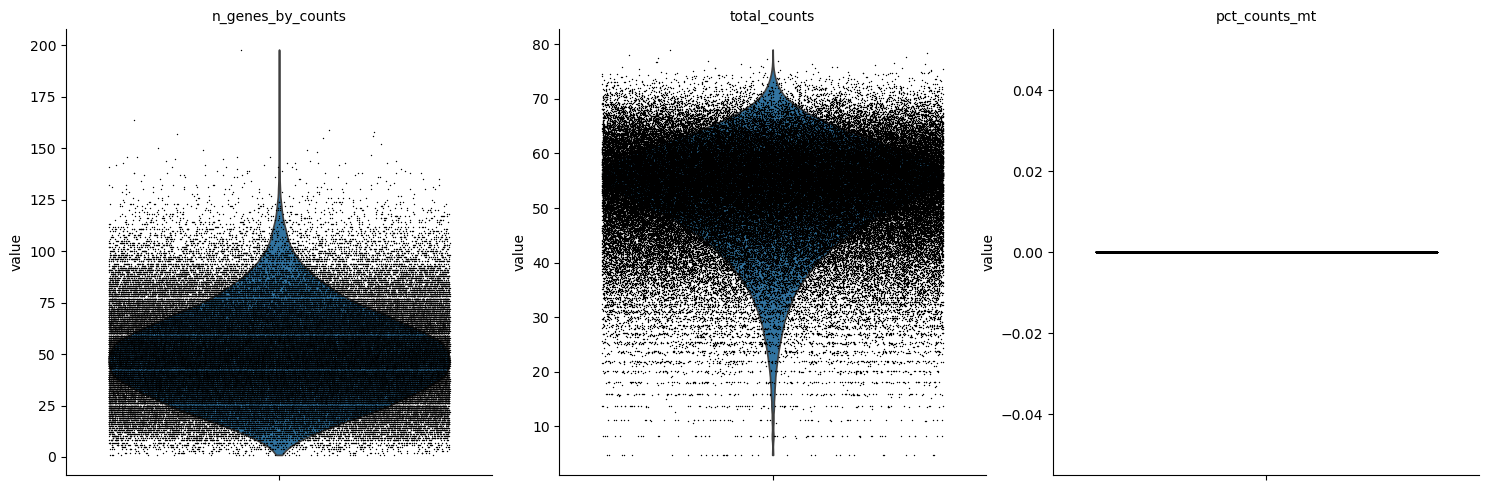

In [19]:
sc.pl.violin(
    adata_gexp_raw,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

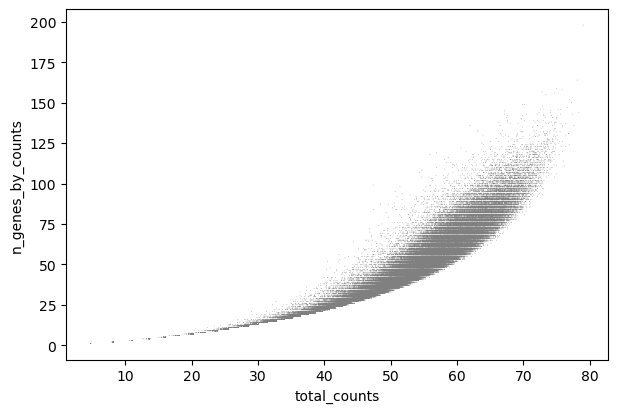

In [20]:
sc.pl.scatter(adata_gexp_raw, "total_counts", "n_genes_by_counts")

In [18]:

print(adata_gexp_raw.shape)

# not doing this step because our resulting data is then out of sync when we merge with morphology
# sc.pp.filter_cells(adata_gexp_raw, min_genes=100) # only cells with at least 100 genes expressed

sc.pp.filter_genes(adata_gexp_raw, min_cells=100) # only genes expressed in at least 100 cells
print(adata_gexp_raw.shape)

(87552, 960)


(87552, 960)


In [21]:
adata_gexp_raw.layers["counts"] = adata_gexp_raw.X.copy()
sc.pp.normalize_total(adata_gexp_raw)
sc.pp.log1p(adata_gexp_raw)

#### Subset to HVGs

In [23]:
sc.pp.highly_variable_genes(adata_gexp_raw, flavor="seurat", batch_key="sample")
adata_gexp_hvg = adata_gexp_raw[:, adata_gexp_raw.var["highly_variable"]].copy()
adata_gexp_hvg

AnnData object with n_obs × n_vars = 113203 × 91
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden', 'Adipocytes_score', 'B_cells_score', 'Breast_cancer_score', 'Breast_glandular_cells_score', 'Breast_myoepithelial_cells_score', 'Dendritic_cells_score', 'Endothelial_cells_score', 'Epithelial_cells_score', 'Fibroblasts_score', 'Immune_cells_score', 'Macrophages_score', 'Mast_cells_score', 'Monocytes_score', 'NK_cells_score', 'Smooth_muscle_cells_score', 'T_cells_score', 'predicted_celltype'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log

#### Integrate

In [25]:
sc.tl.pca(adata_gexp_hvg)
sce.pp.harmony_integrate(adata_gexp_hvg, key="sample", max_iter_harmony=2)

2025-05-21 23:27:32,149 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-05-21 23:27:44,525 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-05-21 23:27:45,086 - harmonypy - INFO - Iteration 1 of 2
2025-05-21 23:28:43,337 - harmonypy - INFO - Iteration 2 of 2
2025-05-21 23:29:40,775 - harmonypy - INFO - Stopped before convergence


In [26]:
sc.pp.neighbors(adata_gexp_hvg, use_rep="X_pca_harmony")
sc.tl.umap(adata_gexp_hvg)

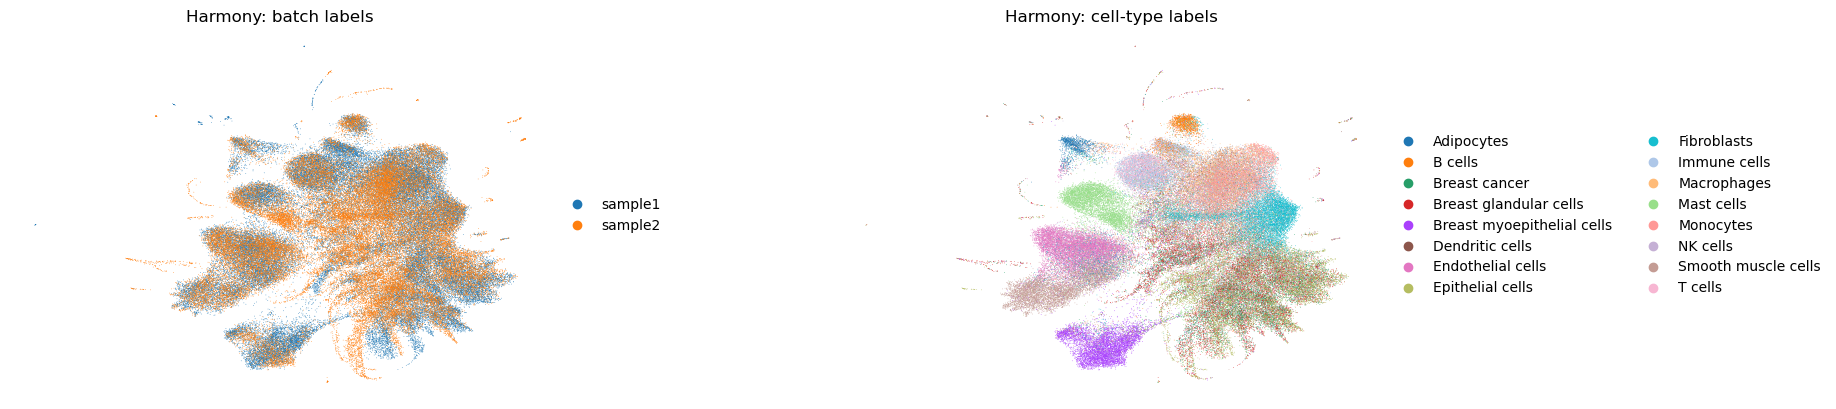

In [27]:
sc.pl.umap(
    adata_gexp_hvg,
    color=["sample", "predicted_celltype"],
    wspace=0.4,
    title=["Harmony: batch labels", "Harmony: cell‐type labels"],
    frameon=False,
)

In [107]:
new_obs_names = [
    f"{'s1' if sample == 'sample1' else 's2'}-{old_name}"
    for old_name, sample in zip(adata_gexp_hvg.obs.cell_id, adata_gexp_hvg.obs["sample"])
]
adata_gexp_hvg.obs_names = new_obs_names

In [108]:
adata_gexp_hvg.obs

,cell_id,transcript_counts,control_probe_counts,control_codeword_counts,total_counts,cell_area,nucleus_area,region,sample,n_genes_by_counts,...,Epithelial_cells_score,Fibroblasts_score,Immune_cells_score,Macrophages_score,Mast_cells_score,Monocytes_score,NK_cells_score,Smooth_muscle_cells_score,T_cells_score,predicted_celltype
s1-41189,41189,222,0,0,70.262589,212.866563,49.220312,cell_circles,sample1,98,...,-0.285647,0.013188,-0.386753,-0.152401,-0.056226,-0.190969,-0.114832,0.183085,-0.048610,Adipocytes
s1-174842,174842,135,0,0,64.307129,126.347188,8.037813,cell_circles,sample1,74,...,-0.063004,-0.096821,-0.083749,0.083670,-0.085120,0.110979,0.012362,-0.087251,-0.062735,Adipocytes
s1-126966,126966,70,0,0,56.220409,104.220625,18.243125,cell_circles,sample1,47,...,-0.276079,0.022820,-0.295929,-0.024960,-0.021954,-0.120597,-0.154878,-0.190069,-0.117785,Adipocytes
s1-43085,43085,171,0,0,52.648125,165.181563,5.644531,cell_circles,sample1,61,...,-0.373689,0.063771,-0.174921,0.062002,-0.153130,0.138751,-0.082430,0.085674,-0.070772,Adipocytes
s1-488410,488410,134,0,0,46.738014,603.558438,9.753750,cell_circles,sample1,45,...,-0.005206,0.059030,-0.084212,-0.090931,-0.185985,-0.167230,-0.135307,0.024822,-0.085685,Adipocytes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s2-45915,45915,54,0,0,55.381203,49.762188,11.063281,cell_circles,sample2,43,...,-0.271014,-0.144638,-0.154468,-0.010602,-0.051489,-0.140332,-0.078989,-0.128984,0.193730,T cells
s2-62737,62737,39,0,0,45.138878,56.355000,14.720937,cell_circles,sample2,29,...,-0.167122,0.008609,0.000000,0.048458,-0.092846,-0.105302,0.142434,-0.004375,0.318250,T cells
s2-131822,131822,99,0,0,60.565380,135.965469,18.288281,cell_circles,sample2,61,...,-0.251930,0.008866,-0.209274,0.153372,-0.131726,-0.141376,-0.017836,-0.197339,0.337488,T cells
s2-178956,178956,25,0,0,42.456924,63.354219,20.591250,cell_circles,sample2,24,...,-0.233343,0.039242,-0.116265,-0.122078,0.000000,-0.193774,-0.118907,-0.106155,0.196511,T cells


In [109]:
adata_gexp_hvg.write(data_dir / "10x_adata_gexp_filtered.h5ad")

## Morphology: Run PyCytoMiner workflow
following https://github.com/scverse/squidpy_notebooks/blob/add_cpmeasure_notebook/tutorials/tutorial_cpmeasure.ipynb

In [76]:
# how many duplicate obs_names?
print(sample1_morphology.obs_names.duplicated().sum(), "dup obs in sample1")
print(sample2_morphology.obs_names.duplicated().sum(), "dup obs in sample2")

# how many duplicate var_names?
print(sample1_morphology.var_names.duplicated().sum(), "dup var in sample1")
print(sample2_morphology.var_names.duplicated().sum(), "dup var in sample2")


0 dup obs in sample1
0 dup obs in sample2
12 dup var in sample1
12 dup var in sample2


In [80]:
sample1_morphology.var_names_make_unique()
sample2_morphology.var_names_make_unique()

In [82]:
sample1_morphology.obs_names = [
    f"{'s1' if sample == 'sample1' else 's2'}-{old_name}"
    for old_name, sample in zip(sample1_morphology.obs.cell_id, sample1_morphology.obs["sample"])
]
sample2_morphology.obs_names = [
    f"{'s1' if sample == 'sample1' else 's2'}-{old_name}"
    for old_name, sample in zip(sample2_morphology.obs.cell_id, sample2_morphology.obs["sample"])
]

adata_morphology_raw = ad.concat([sample1_morphology, sample2_morphology], axis=0)
adata_morphology_raw.write(data_dir / "10x_adata_morphology_raw.h5ad")
adata_morphology_raw

AnnData object with n_obs × n_vars = 113203 × 957
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden', 'Adipocytes_score', 'B_cells_score', 'Breast_cancer_score', 'Breast_glandular_cells_score', 'Breast_myoepithelial_cells_score', 'Dendritic_cells_score', 'Endothelial_cells_score', 'Epithelial_cells_score', 'Fibroblasts_score', 'Immune_cells_score', 'Macrophages_score', 'Mast_cells_score', 'Monocytes_score', 'NK_cells_score', 'Smooth_muscle_cells_score', 'T_cells_score', 'predicted_celltype'

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/tools/_utils.py:41: UserWarning: You’re trying to run this on 957 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(
/tmp/ipykernel_3208298/4278073994.py:5: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_morphology_raw)


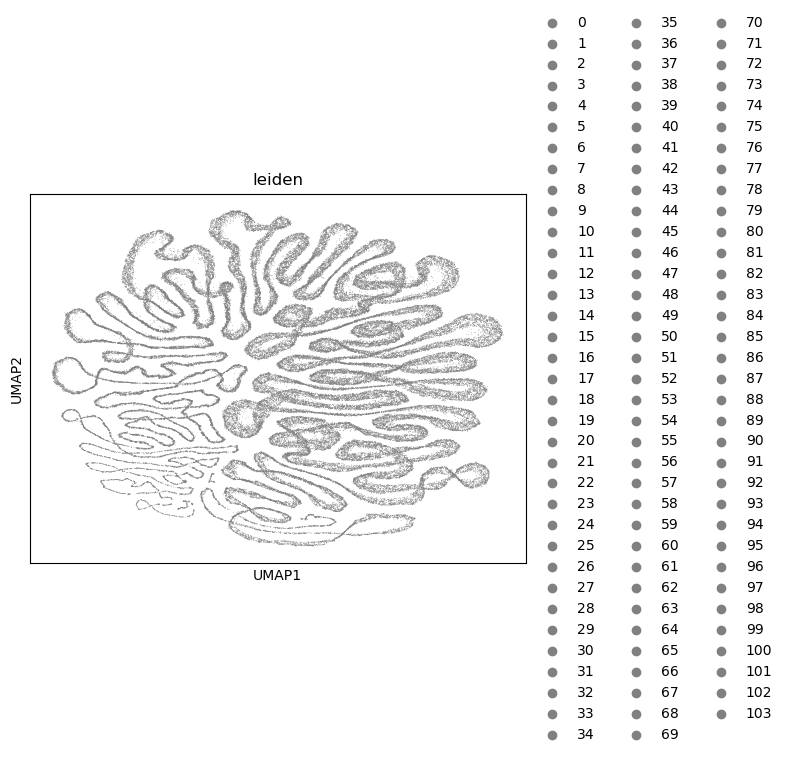

In [83]:
# we expect this to be bad

sc.pp.neighbors(adata_morphology_raw)
sc.tl.umap(adata_morphology_raw)
sc.tl.leiden(adata_morphology_raw)
sc.pl.umap(adata_morphology_raw, color="leiden")

In [84]:
adata_morphology_df = adata_morphology_raw.to_df()

scaler = RobustMAD(epsilon=1e-18)
fitted_scaler = scaler.fit(adata_morphology_df)
fitted_scaled = fitted_scaler.transform(adata_morphology_df)

adata_morphology_df_scaled = pd.DataFrame(
    fitted_scaled,
    columns=adata_morphology_df.columns,
    index=adata_morphology_df.index,
)
adata_morphology_df_scaled

,intensity_max_0,intensity_min_0,intensity_mean_0,intensity_std_0,RadialDistribution_FracAtD_1of4_0,RadialDistribution_MeanFrac_1of4_0,RadialDistribution_RadialCV_1of4_0,RadialDistribution_FracAtD_2of4_0,RadialDistribution_MeanFrac_2of4_0,RadialDistribution_RadialCV_2of4_0,...,intensity_max_0-1,intensity_min_0-1,intensity_std_1-1,intensity_max_1-1,intensity_mean_1-1,intensity_min_1-1,intensity_max_2-1,intensity_min_2-1,intensity_mean_2-1,intensity_std_2-1
s1-1,-4.000000e+18,0.562076,0.581638,-1.239957,0.922628,0.824695,-0.536309,1.237258,1.007373,-0.847450,...,-4.000000e+18,0.562076,0.395638,0.674491,2.870101,-0.174062,0.899321,-0.527862,1.340735,0.258911
s1-2,0.000000e+00,0.599547,0.233796,-0.831143,0.803676,1.959727,-0.481110,-0.813411,-0.372468,1.800266,...,0.000000e+00,0.599547,2.095676,1.042395,1.209922,-0.435155,0.899321,-0.997073,-0.418974,1.668844
s1-131075,-4.000000e+18,1.067944,0.511676,-0.973382,0.259666,0.154669,-0.842130,-0.148850,-0.170732,1.041749,...,-4.000000e+18,1.067944,-0.580693,0.551856,1.473144,1.370739,-0.674491,1.231679,0.922097,-1.107599
s1-524292,0.000000e+00,1.049208,1.320477,-1.222772,-0.189407,-0.386665,-0.456952,0.902130,0.610713,0.442815,...,0.000000e+00,1.049208,-0.354885,0.613173,-0.352240,0.652733,0.899321,0.762468,-0.131313,-0.535674
s1-131077,0.000000e+00,0.936793,0.767819,-0.806295,0.527688,0.381249,0.056851,0.101735,0.025922,-0.595694,...,0.000000e+00,0.936793,-0.416581,0.367904,0.714915,0.957342,-0.674491,0.967748,0.528521,-0.919866
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s2-262099,0.000000e+00,-0.505868,1.252527,-0.307392,-0.049604,-0.047704,-1.009581,0.822756,0.770997,-0.216085,...,0.000000e+00,-0.505868,-1.028712,-1.287664,-0.448250,-0.761522,-0.899321,-0.615839,0.007665,-0.450302
s2-262102,-5.000000e+18,0.206094,-1.970944,0.944924,0.553790,0.269878,1.817373,-0.488998,-0.597242,-1.618549,...,-5.000000e+18,0.206094,-0.052013,-3.495088,-1.796578,0.000000,-2.922793,0.058651,-2.305098,0.737570
s2-262103,0.000000e+00,-0.224830,-0.157539,0.238009,0.448443,0.728555,1.721584,-1.097813,-0.986227,0.472771,...,0.000000e+00,-0.224830,-0.312499,0.245269,0.128200,-0.369882,0.674491,-0.351908,0.181782,-0.110973
s2-262108,0.000000e+00,-1.648755,-1.669758,2.349550,0.082189,0.179019,-0.821052,-1.344082,-1.290817,-0.705219,...,0.000000e+00,-1.648755,1.887158,0.429221,-1.091687,-1.610075,-0.449661,-1.554261,-1.636873,2.735081


In [92]:
feature_select_opts = [
    # "variance_threshold",
    "drop_na_columns",
    "correlation_threshold",
    "blocklist",
    "drop_outliers",
]

adata_morphology_df_scaled_filtered = pycytominer.feature_select(
    profiles=adata_morphology_df_scaled,
    features=adata_morphology_df_scaled.columns.tolist(),
    samples="all",
    operation=feature_select_opts,
)
adata_morphology_df_scaled_filtered


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,RadialDistribution_FracAtD_1of4_0,RadialDistribution_RadialCV_1of4_0,RadialDistribution_FracAtD_2of4_0,RadialDistribution_RadialCV_2of4_0,RadialDistribution_FracAtD_3of4_0,RadialDistribution_RadialCV_3of4_0,RadialDistribution_FracAtD_4of4_0,RadialDistribution_RadialCV_4of4_0,RadialDistribution_ZernikePhase_1_1_0,RadialDistribution_ZernikeMagnitude_3_1_0,...,Correlation_Pearson_0_2,Correlation_Slope_0_2,Correlation_RWC_1_0_2,solidity_1_2,Correlation_Slope_1_2,Correlation_RWC_1_1_2,eccentricity,centroid_0,centroid_1,extent
s1-1,0.922628,-0.536309,1.237258,-0.847450,-0.487335,-0.125687,-1.568999,-0.212905,-1.264457,0.567111,...,0.414845,10.673187,2.400280,1.292099,-0.084678,-2.988232,0.095498,3.985352,2.587565,1.026992
s1-2,0.803676,-0.481110,-0.813411,1.800266,0.965230,0.478736,-0.841150,0.940875,-0.064345,1.991121,...,0.201343,9.851169,2.319955,-1.613069,-0.101050,-1.587162,1.104805,2.996042,0.774029,0.275782
s1-131075,0.259666,-0.842130,-0.148850,1.041749,-0.186578,-0.758293,0.189426,-1.110189,-0.148943,1.101236,...,-0.942403,-0.626208,-1.371493,0.904109,-1.679661,-1.981797,0.257475,1.555266,0.153201,-0.941820
s1-524292,-0.189407,-0.456952,0.902130,0.442815,-1.277851,-0.338166,0.675330,-1.687710,0.577018,-0.840772,...,-4.289709,-0.959549,-1.969298,1.424107,-0.638844,0.540090,-1.601472,3.001318,2.021698,0.649452
s1-131077,0.527688,0.056851,0.101735,-0.595694,0.100430,-1.473977,-0.619001,-1.359174,0.174639,0.504643,...,-2.448649,-1.565286,-1.268949,0.308328,-1.463014,-0.818689,-0.030577,2.052322,3.864879,-0.167634
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s2-262099,-0.049604,-1.009581,0.822756,-0.216085,0.880113,0.424351,-1.546407,2.318395,-1.311558,2.541498,...,0.347460,-0.021347,-0.977965,1.152997,1.379032,0.886551,0.328234,1.572031,0.019675,1.107041
s2-262102,0.553790,1.817373,-0.488998,-1.618549,0.009428,0.402122,0.040370,-0.244303,0.404684,-0.258207,...,0.550643,-0.096853,0.965155,-0.055966,1.526328,0.389043,0.037404,-1.439414,-1.038725,0.055700
s2-262103,0.448443,1.721584,-1.097813,0.472771,1.339247,-0.035303,-0.573299,-0.250280,0.690073,1.354732,...,-0.032114,-0.671544,0.407421,-2.412298,0.214974,0.541092,0.229995,1.504151,0.944521,-1.319986
s2-262108,0.082189,-0.821052,-1.344082,-0.705219,1.698370,-0.114520,-0.317846,0.147224,-0.762712,0.190776,...,0.855993,0.665861,-0.033081,-0.569320,1.145458,0.169053,0.079334,0.173243,-0.264403,0.100119


In [93]:
adata_morphology_filtered = ad.AnnData(
    X=adata_morphology_df_scaled_filtered,
    obs=adata_morphology_raw.obs,
)
del adata_morphology_filtered.obs["leiden"]
adata_morphology_filtered

AnnData object with n_obs × n_vars = 113203 × 246
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'Adipocytes_score', 'B_cells_score', 'Breast_cancer_score', 'Breast_glandular_cells_score', 'Breast_myoepithelial_cells_score', 'Dendritic_cells_score', 'Endothelial_cells_score', 'Epithelial_cells_score', 'Fibroblasts_score', 'Immune_cells_score', 'Macrophages_score', 'Mast_cells_score', 'Monocytes_score', 'NK_cells_score', 'Smooth_muscle_cells_score', 'T_cells_score', 'predicted_celltype'

In [94]:
del adata_morphology_filtered.uns["leiden_colors"]

KeyError: 'leiden_colors'

In [95]:
sc.pp.neighbors(adata_morphology_filtered)
sc.tl.umap(adata_morphology_filtered)
sc.tl.leiden(adata_morphology_filtered)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/tools/_utils.py:41: UserWarning: You’re trying to run this on 246 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(


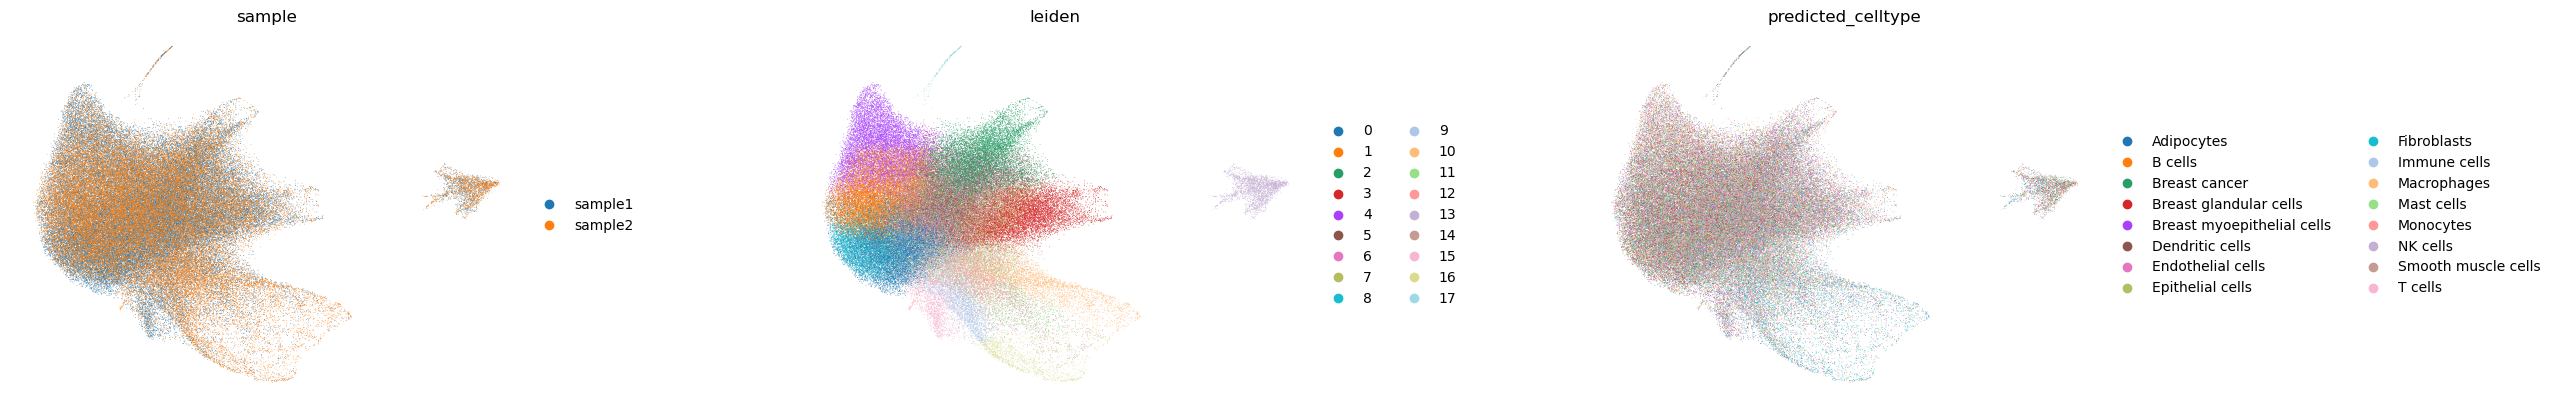

In [96]:
sc.pl.umap(
    adata_morphology_filtered,
    color=["sample", "leiden", "predicted_celltype"],
    wspace=0.4,
    frameon=False,
)

In [97]:
adata_morphology_filtered.write(data_dir / "10x_adata_morphology_filtered.h5ad")
adata_morphology_filtered

AnnData object with n_obs × n_vars = 113203 × 246
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'Adipocytes_score', 'B_cells_score', 'Breast_cancer_score', 'Breast_glandular_cells_score', 'Breast_myoepithelial_cells_score', 'Dendritic_cells_score', 'Endothelial_cells_score', 'Epithelial_cells_score', 'Fibroblasts_score', 'Immune_cells_score', 'Macrophages_score', 'Mast_cells_score', 'Monocytes_score', 'NK_cells_score', 'Smooth_muscle_cells_score', 'T_cells_score', 'predicted_celltype', 'leiden'
    uns: 'pca', 'neighbors', 'umap', 'leiden', 'sample_colors', 'leiden_colors', 'predicted_celltype_colors'
    obsm: 'X_pca', 'X

## Merge and prepare for training

In [102]:
adata_morphology_filtered.obs

,cell_id,transcript_counts,control_probe_counts,control_codeword_counts,total_counts,cell_area,nucleus_area,region,sample,n_genes_by_counts,...,Fibroblasts_score,Immune_cells_score,Macrophages_score,Mast_cells_score,Monocytes_score,NK_cells_score,Smooth_muscle_cells_score,T_cells_score,predicted_celltype,leiden
s1-1,1,89,0,0,89.0,686.555625,34.499375,cell_circles,sample1,50,...,-0.155881,-0.056272,0.150137,0.562722,-0.037515,-0.038367,0.011410,-0.029879,Mast cells,10
s1-2,2,61,0,0,61.0,277.259375,39.782656,cell_circles,sample1,45,...,0.151087,-0.215302,-0.038415,-0.023922,0.287070,-0.073399,-0.091561,-0.039396,Monocytes,16
s1-131075,131075,122,0,0,122.0,197.513438,28.900000,cell_circles,sample1,45,...,0.731821,-0.440659,-0.096707,0.000000,-0.060507,-0.075112,0.351071,-0.027540,Fibroblasts,3
s1-524292,524292,109,0,0,109.0,486.558594,15.307969,cell_circles,sample1,46,...,0.881437,-0.368421,-0.037219,-0.016302,-0.086094,-0.062799,0.028916,0.008849,Fibroblasts,14
s1-131077,131077,210,0,0,210.0,407.399688,39.240781,cell_circles,sample1,66,...,0.727997,-0.408584,-0.015405,-0.009909,-0.068419,-0.018974,0.003815,-0.041475,Fibroblasts,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s2-262099,262099,52,0,0,52.0,189.656250,8.940938,cell_circles,sample2,37,...,0.124902,-0.272055,-0.056121,-0.052647,-0.142024,-0.079285,0.030853,-0.064486,Endothelial cells,12
s2-262102,262102,37,0,0,37.0,24.068281,13.366250,cell_circles,sample2,27,...,-0.103744,0.000000,-0.064463,0.000000,-0.031833,0.000000,0.022997,-0.027816,Epithelial cells,4
s2-262103,262103,201,0,0,201.0,150.731562,64.573437,cell_circles,sample2,77,...,-0.113503,-0.098503,-0.079180,-0.037787,-0.116630,-0.032536,-0.088331,0.009465,Breast glandular cells,3
s2-262108,262108,172,0,0,172.0,100.879063,34.454219,cell_circles,sample2,60,...,-0.126613,-0.311103,-0.062250,-0.024840,-0.054021,-0.053029,0.080120,-0.005494,Breast glandular cells,1


In [101]:
adata_gexp_hvg.obs

,cell_id,transcript_counts,control_probe_counts,control_codeword_counts,total_counts,cell_area,nucleus_area,region,sample,n_genes_by_counts,...,Epithelial_cells_score,Fibroblasts_score,Immune_cells_score,Macrophages_score,Mast_cells_score,Monocytes_score,NK_cells_score,Smooth_muscle_cells_score,T_cells_score,predicted_celltype
41188,41189,222,0,0,70.262589,212.866563,49.220312,cell_circles,sample1,98,...,-0.285647,0.013188,-0.386753,-0.152401,-0.056226,-0.190969,-0.114832,0.183085,-0.048610,Adipocytes
174841,174842,135,0,0,64.307129,126.347188,8.037813,cell_circles,sample1,74,...,-0.063004,-0.096821,-0.083749,0.083670,-0.085120,0.110979,0.012362,-0.087251,-0.062735,Adipocytes
126965,126966,70,0,0,56.220409,104.220625,18.243125,cell_circles,sample1,47,...,-0.276079,0.022820,-0.295929,-0.024960,-0.021954,-0.120597,-0.154878,-0.190069,-0.117785,Adipocytes
43084,43085,171,0,0,52.648125,165.181563,5.644531,cell_circles,sample1,61,...,-0.373689,0.063771,-0.174921,0.062002,-0.153130,0.138751,-0.082430,0.085674,-0.070772,Adipocytes
488409,488410,134,0,0,46.738014,603.558438,9.753750,cell_circles,sample1,45,...,-0.005206,0.059030,-0.084212,-0.090931,-0.185985,-0.167230,-0.135307,0.024822,-0.085685,Adipocytes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45914-1,45915,54,0,0,55.381203,49.762188,11.063281,cell_circles,sample2,43,...,-0.271014,-0.144638,-0.154468,-0.010602,-0.051489,-0.140332,-0.078989,-0.128984,0.193730,T cells
62736-1,62737,39,0,0,45.138878,56.355000,14.720937,cell_circles,sample2,29,...,-0.167122,0.008609,0.000000,0.048458,-0.092846,-0.105302,0.142434,-0.004375,0.318250,T cells
131821-1,131822,99,0,0,60.565380,135.965469,18.288281,cell_circles,sample2,61,...,-0.251930,0.008866,-0.209274,0.153372,-0.131726,-0.141376,-0.017836,-0.197339,0.337488,T cells
178955-1,178956,25,0,0,42.456924,63.354219,20.591250,cell_circles,sample2,24,...,-0.233343,0.039242,-0.116265,-0.122078,0.000000,-0.193774,-0.118907,-0.106155,0.196511,T cells


In [110]:
adata_both = ad.AnnData(
    X=pd.concat([adata_morphology_filtered.to_df(), adata_gexp_hvg.to_df()], axis=1),
    obs=adata_morphology_filtered.obs,
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/utils.py:311: UserWarning: X converted to numpy array with dtype float64
  warnings.warn(f"{name} converted to numpy array with dtype {arr.dtype}")


In [111]:
feat_origins = []

for feat in adata_both.var_names:
    if feat in adata_morphology_filtered.var_names:
        feat_origins.append("morphology")
    elif feat in adata_gexp_hvg.var_names:
        feat_origins.append("gexp")

adata_both.var["feat_type"] = feat_origins

In [112]:
adata_both

AnnData object with n_obs × n_vars = 113203 × 337
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'Adipocytes_score', 'B_cells_score', 'Breast_cancer_score', 'Breast_glandular_cells_score', 'Breast_myoepithelial_cells_score', 'Dendritic_cells_score', 'Endothelial_cells_score', 'Epithelial_cells_score', 'Fibroblasts_score', 'Immune_cells_score', 'Macrophages_score', 'Mast_cells_score', 'Monocytes_score', 'NK_cells_score', 'Smooth_muscle_cells_score', 'T_cells_score', 'predicted_celltype', 'leiden'
    var: 'feat_type'

## Write to disk for training

In [113]:
adata_both.write(data_dir / "10x_adata_both_modalities_for_training.h5ad")